In [2]:
import pandas as pd
import numpy as np
import re
import unicodedata
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 140
sns.set_theme(style="whitegrid", palette="Set2")

BASE_DIR = Path(r"C:\Projet Niger Labor Market\niger_jobs_scraper\data\cleaned")
emp = pd.read_csv(BASE_DIR / "offres_niger_emploi.csv")

def norm_text(s):
    if pd.isna(s):
        return ""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode("utf-8").lower()
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def norm_titre_isco(s):
    t = norm_text(s)
    t = re.sub(r"\b(?:e|trice|cheffe|s)\b", " ", t)
    return re.sub(r"\s+", " ", t).strip()



In [3]:
# ==============================================================================
# 1. CLASSIFICATION METIERS ISCO-08 (CITP-08 - GRANDS GROUPES BIT)
# ==============================================================================
def classer_isco08(row):
    t = norm_titre_isco(row["titre_poste"])
    # Groupe 1 : Directeurs, cadres de direction et gérants
    if any(k in t for k in [
        "directeur", "responsable pays", "area manager", "chef de mission",
        "field operations manager", "roving manager", "supply chain team leader",
        "responsable des operations"
    ]):
        return "1. Directeurs & Cadres de direction"
    # Groupe 2 : Professions intellectuelles et scientifiques
    if any(k in t for k in [
        "medecin", "pharmacien", "ingenieur", "agronome", "controleur de gestion",
        "auditeur", "analystes credit", "evaluat", "etude de base", "consultant",
        "coordinateur technique", "responsable de programme", "chargee genre",
        "manager regional des ressources humaines", "senior partnership manager",
        "conseiller acces humanitaire", "food safety", "tom2 pro", "digitalisation",
        "responsable administratif et financier", "formateurs"
    ]):
        return "2. Professions intellectuelles & scientifiques"
    # Groupe 3 : Professions intermédiaires & Techniciens
    if any(k in t for k in [
        "infirmier", "comptable", "superviseur", "hse", "charge", "facilitateur",
        "officer", "associate", "gestionnaire", "stagiaire", "benevoles",
        "enseignement", "enseignant", "laborantin", "assurance qualite",
        "reconversion", "assistant finance"
    ]):
        return "3. Professions intermédiaires & Techniciens"
    # Groupe 4 : Employés de type administratif
    if any(k in t for k in ["caissiere", "billetterie", "payroll"]):
        return "4. Employés administratifs & accueil"
    # Groupe 5 : Personnel des services directs & vente
    if any(k in t for k in ["cuisinier", "commercial"]):
        return "5. Personnel des services & vente"
    # Groupe 7 : Métiers qualifiés de l'industrie et du BTP
    if any(k in t for k in ["monteur", "raffinerie", "operateurs"]):
        return "7. Métiers qualifiés de l'industrie & BTP"
    # Groupe 8 : Conducteurs d'engins & mécanique
    if any(k in t for k in ["chauffeur"]):
        return "8. Conducteurs d'engins & mécanique"
    # Groupe 9 : Professions élémentaires
    if any(k in t for k in ["enqueteur"]):
        return "9. Professions élémentaires (Enquêteurs)"
    return "0. Marchés / Fournitures (Hors ISCO)"

emp["isco08_groupe"] = emp.apply(classer_isco08, axis=1)

print("=== 1. DISTRIBUTION DES PROFESSIONS SELON ISCO-08 (BIT) ===")
print(pd.DataFrame({
    "Effectif": emp["isco08_groupe"].value_counts(),
    "Part_%": (emp["isco08_groupe"].value_counts(normalize=True) * 100).round(1)
}))



=== 1. DISTRIBUTION DES PROFESSIONS SELON ISCO-08 (BIT) ===
                                                Effectif  Part_%
isco08_groupe                                                   
3. Professions intermédiaires & Techniciens           26    37.1
2. Professions intellectuelles & scientifiques        23    32.9
1. Directeurs & Cadres de direction                   11    15.7
4. Employés administratifs & accueil                   3     4.3
0. Marchés / Fournitures (Hors ISCO)                   3     4.3
7. Métiers qualifiés de l'industrie & BTP              1     1.4
8. Conducteurs d'engins & mécanique                    1     1.4
9. Professions élémentaires (Enquêteurs)               1     1.4
5. Personnel des services & vente                      1     1.4


In [4]:
# ==============================================================================
# 2. EXTRACTION DE LA TRIADE DES COMPETENCES (SAVOIRS, SAVOIR-FAIRE, SAVOIR-ETRE)
# ==============================================================================
emp["texte_nlp"] = (
    emp["titre_poste"].fillna("") + " " +
    emp["profil_exige_corpus"].fillna("") + " " +
    emp["description_propre"].fillna("")
).apply(norm_text)

SAVOIRS_DICT = {
    "Comptabilité, Finance & Audit": r"\b(?:comptabilite|financ\w+|audit|fiscal\w+|budget\w*|tresorerie|controle de gestion)\b",
    "Sécurité humanitaire & Accès / HSE": r"\b(?:acces humanitaire|securite|hse|gestion des risques|sante au travail)\b",
    "Protection, Genre & Inclusion sociale": r"\b(?:genre|inclusion|protection|vbg|violences basees sur le genre|droits humains|enfant\w*)\b",
    "Agronomie, Sécurité alimentaire & Environnement": r"\b(?:agronom\w*|securite alimentaire|agriculture|elevage|environnement|climat\w*)\b",
    "Santé publique, Nutrition & Médecine": r"\b(?:sante publique|epidemiologie|vaccination|nutrition|medical\w*|soins|pharmacie|one health)\b",
    "Logistique, Achats & Supply Chain": r"\b(?:logistique|supply chain|approvisionnement|achats|passation des marches|stock\w*)\b",
    "Gestion de projet & Cycle PCM": r"\b(?:gestion de projet|cycle de projet|planification|mise en oeuvre|cadre logique)\b",
    "Suivi-Évaluation & Redevabilité (MEAL)": r"\b(?:suivi evaluation|suivi et evaluation|meal|redevabilite|indicateurs|enquete\w*|collecte de donnees)\b",
    "Eau, Hygiène & Assainissement (WASH/ATPC)": r"\b(?:wash|assainissement|hygiene|atpc|eau potable|forage\w*)\b",
    "Génie civil, Industrie & Maintenance": r"\b(?:genie civil|construction|structure\w* metallique\w*|maintenance|mecanique|raffinerie|geolog\w*)\b",
}

SAVOIR_FAIRE_DICT = {
    "Coordination partenariale & Plaidoyer": r"\b(?:coordination|partenariat\w*|plaidoyer|representation|parties prenantes|autorites locales)\b",
    "Supervision d'équipe & Management terrain": r"\b(?:supervision|encadrement|management|gestion d equipe|leadership)\b",
    "Animation communautaire & Sensibilisation": r"\b(?:mobilisation communautaire|sensibilisation|animation|formation des|renforcement des capacites)\b",
    "Conduite terrain & Mobilité (Permis/Moto)": r"\b(?:permis de conduire|conduite|moto|deplacements frequents|zone\w* rurale\w*)\b",
    "Maîtrise de l'anglais professionnel": r"\b(?:anglais|english|bilingue)\b",
    "Rédaction de rapports & Synthèse": r"\b(?:redaction de rapport\w*|rapports d activite|rapports periodiques|synthese|redactionnelle\w*)\b",
    "Analyse de données & Statistiques": r"\b(?:analyse de donnees|statistique\w*|traitement des donnees|base de donnees|cartographie)\b",
    "Gestion budgétaire & Contrôle interne": r"\b(?:gestion budgetaire|suivi budgetaire|controle interne|procedures financieres|pieces justificatives)\b",
}

OUTILS_DICT = {
    "Pack MS Office (Excel, Word, PPT)": r"\b(?:ms office|microsoft office|excel|word|powerpoint|pack office)\b",
    "Logiciels Comptables (Sage, Tom2Pro, SAP)": r"\b(?:sage|saari|tom2\s*pro|tompro|sap|logiciel comptable)\b",
    "Stats & SIG (SPSS, Stata, R, Python, QGIS, DHIS2)": r"\b(?:spss|stata|python|qgis|arcgis|dhis2|power bi|r studio)\b",
    "KoboToolbox / ODK / Collecte mobile": r"\b(?:kobo\w*|odk|open data kit|collecte mobile|tablette\w*)\b",
}

SAVOIR_ETRE_DICT = {
    "Rigueur, Organisation & Autonomie": r"\b(?:rigueur|rigoureux|organis\w*|autonomie|autonome|sens de l organisation)\b",
    "Communication & Écoute interculturelle": r"\b(?:communication|aisance relationnelle|ecoute|interculturel\w*|diplomatie)\b",
    "Intégrité, Éthique & Confidentialité": r"\b(?:integrite|ethique|confidentialite|impartialite|redevabilite)\b",
    "Résistance au stress & Réactivité": r"\b(?:sous pression|stress|reacti\w*|disponibilite|flexibilite|adaptabilite)\b",
    "Travail en équipe & Collaboration": r"\b(?:travail en equipe|esprit d equipe|collaborat\w*)\b",
}

def extraire_categories(texte, dictionnaire):
    return [label for label, pat in dictionnaire.items() if re.search(pat, texte)]

emp["savoirs"] = emp["texte_nlp"].apply(lambda x: extraire_categories(x, SAVOIRS_DICT))
emp["savoir_faire"] = emp["texte_nlp"].apply(lambda x: extraire_categories(x, SAVOIR_FAIRE_DICT))
emp["outils"] = emp["texte_nlp"].apply(lambda x: extraire_categories(x, OUTILS_DICT))
emp["savoir_etre"] = emp["texte_nlp"].apply(lambda x: extraire_categories(x, SAVOIR_ETRE_DICT))

for nom, col in [
    ("SAVOIRS (Connaissances disciplinaires)", "savoirs"),
    ("SAVOIR-FAIRE (Compétences opérationnelles)", "savoir_faire"),
    ("OUTILS & LOGICIELS", "outils"),
    ("SAVOIR-ÊTRE (Soft Skills)", "savoir_etre"),
]:
    s = emp[col].explode().dropna().value_counts()
    print(f"\n=== 2. {nom} (n=70) ===")
    print(pd.DataFrame({"Offres": s, "Taux_%": (s / len(emp) * 100).round(1)}))



=== 2. SAVOIRS (Connaissances disciplinaires) (n=70) ===
                                                 Offres  Taux_%
savoirs                                                        
Comptabilité, Finance & Audit                        41    58.6
Sécurité humanitaire & Accès / HSE                   40    57.1
Protection, Genre & Inclusion sociale                36    51.4
Agronomie, Sécurité alimentaire & Environnement      31    44.3
Santé publique, Nutrition & Médecine                 28    40.0
Logistique, Achats & Supply Chain                    25    35.7
Gestion de projet & Cycle PCM                        23    32.9
Suivi-Évaluation & Redevabilité (MEAL)               23    32.9
Eau, Hygiène & Assainissement (WASH/ATPC)            23    32.9
Génie civil, Industrie & Maintenance                 17    24.3

=== 2. SAVOIR-FAIRE (Compétences opérationnelles) (n=70) ===
                                           Offres  Taux_%
savoir_faire                                          

In [5]:
# ==============================================================================
# 3. ANALYSE LEXICOMETRIQUE TF-IDF : ONG/ONU VS SECTEUR PRIVE
# ==============================================================================
STOP_FR = {
    "de", "du", "des", "la", "le", "les", "l", "d", "et", "en", "a", "au", "aux",
    "ou", "un", "une", "se", "sa", "son", "ses", "ce", "ces", "cette", "cet",
    "il", "elle", "on", "nous", "vous", "ils", "elles", "y", "ne", "pas", "plus",
    "que", "qui", "quoi", "dont", "ni", "si", "car", "mais", "or", "donc",
    "sur", "sous", "dans", "par", "pour", "avec", "sans", "vers", "chez", "entre",
    "jusque", "depuis", "pendant", "selon", "contre", "malgre", "parmi", "hors",
    "etre", "avoir", "faire", "dire", "aller", "voir", "savoir", "pouvoir", "falloir",
    "vouloir", "venir", "devoir", "prendre", "trouver", "donner", "mettre", "passer",
    "devenir", "tenir", "comprendre", "connaitre", "assurer", "garantir", "veiller",
    "participer", "contribuer", "appuyer", "realiser", "effectuer", "suivre", "gerer",
    "developper", "organiser", "preparer", "verifier", "respecter", "conformement",
    "afin", "ainsi", "alors", "aussi", "autre", "autres", "bien", "comme", "encore",
    "enfin", "ensuite", "environ", "etant", "ete", "faut", "fois", "ici", "jamais",
    "lors", "meme", "memes", "moins", "non", "notamment", "nouveau", "nouvelle",
    "peu", "peut", "peuvent", "plupart", "pourra", "premier", "premiere", "pres", "puis",
    "quand", "quel", "quelle", "quelles", "quels", "quelque", "quelques", "sera",
    "seront", "seul", "seule", "seulement", "soit", "tant", "tel", "telle", "tels", "telles",
    "toujours", "tres", "trop", "via", "voire", "ans", "annee", "annees", "uvre",
    "poste", "candidature", "candidatures", "candidat", "candidats", "niger", "niamey",
    "avis", "recrutement", "offre", "emploi", "mission", "missions", "activites", "travail",
    "mise", "oeuvre", "gestion", "suivi", "niveau", "experience", "formation", "diplome",
    "domaine", "cadre", "sein", "compte", "base", "lieu", "date", "limite", "dossier",
    "besoin", "besoins", "ensemble", "charge", "responsable", "equip", "equipe", "equipes"
}

emp["bloc_employeur"] = np.where(
    emp["type_employeur"] == "Secteur Privé & Cabinets",
    "Secteur Privé & Cabinets",
    "ONG, ONU & Projets"
)
vec = TfidfVectorizer(
    max_features=500, ngram_range=(1, 2),
    stop_words=list(STOP_FR), min_df=3, token_pattern=r"\b[a-z]{3,}\b"
)
X_tfidf = vec.fit_transform(emp["texte_nlp"])
terms = np.array(vec.get_feature_names_out())

print("\n=== 3. TERMES DISCRIMINANTS TF-IDF PAR BLOC D'EMPLOYEURS ===")
for bloc in ["ONG, ONU & Projets", "Secteur Privé & Cabinets"]:
    idx_b = emp["bloc_employeur"] == bloc
    mean_scores = np.asarray(X_tfidf[idx_b.values].mean(axis=0)).ravel()
    top_idx = mean_scores.argsort()[::-1][:10]
    print(f"\n[{bloc}] (n={idx_b.sum()}) :")
    for t, sc in zip(terms[top_idx], mean_scores[top_idx]):
        print(f"  - {t:<28} (score TF-IDF moyen = {sc:.4f})")




=== 3. TERMES DISCRIMINANTS TF-IDF PAR BLOC D'EMPLOYEURS ===

[ONG, ONU & Projets] (n=43) :
  - sante                        (score TF-IDF moyen = 0.0774)
  - projet                       (score TF-IDF moyen = 0.0671)
  - developpement                (score TF-IDF moyen = 0.0601)
  - irc                          (score TF-IDF moyen = 0.0555)
  - securite                     (score TF-IDF moyen = 0.0530)
  - est                          (score TF-IDF moyen = 0.0525)
  - progres                      (score TF-IDF moyen = 0.0512)
  - tout                         (score TF-IDF moyen = 0.0467)
  - programmes                   (score TF-IDF moyen = 0.0444)
  - eam                          (score TF-IDF moyen = 0.0430)

[Secteur Privé & Cabinets] (n=27) :
  - comptable                    (score TF-IDF moyen = 0.0735)
  - comptables                   (score TF-IDF moyen = 0.0689)
  - comptabilite                 (score TF-IDF moyen = 0.0674)
  - professionnelle              (score TF-IDF moye

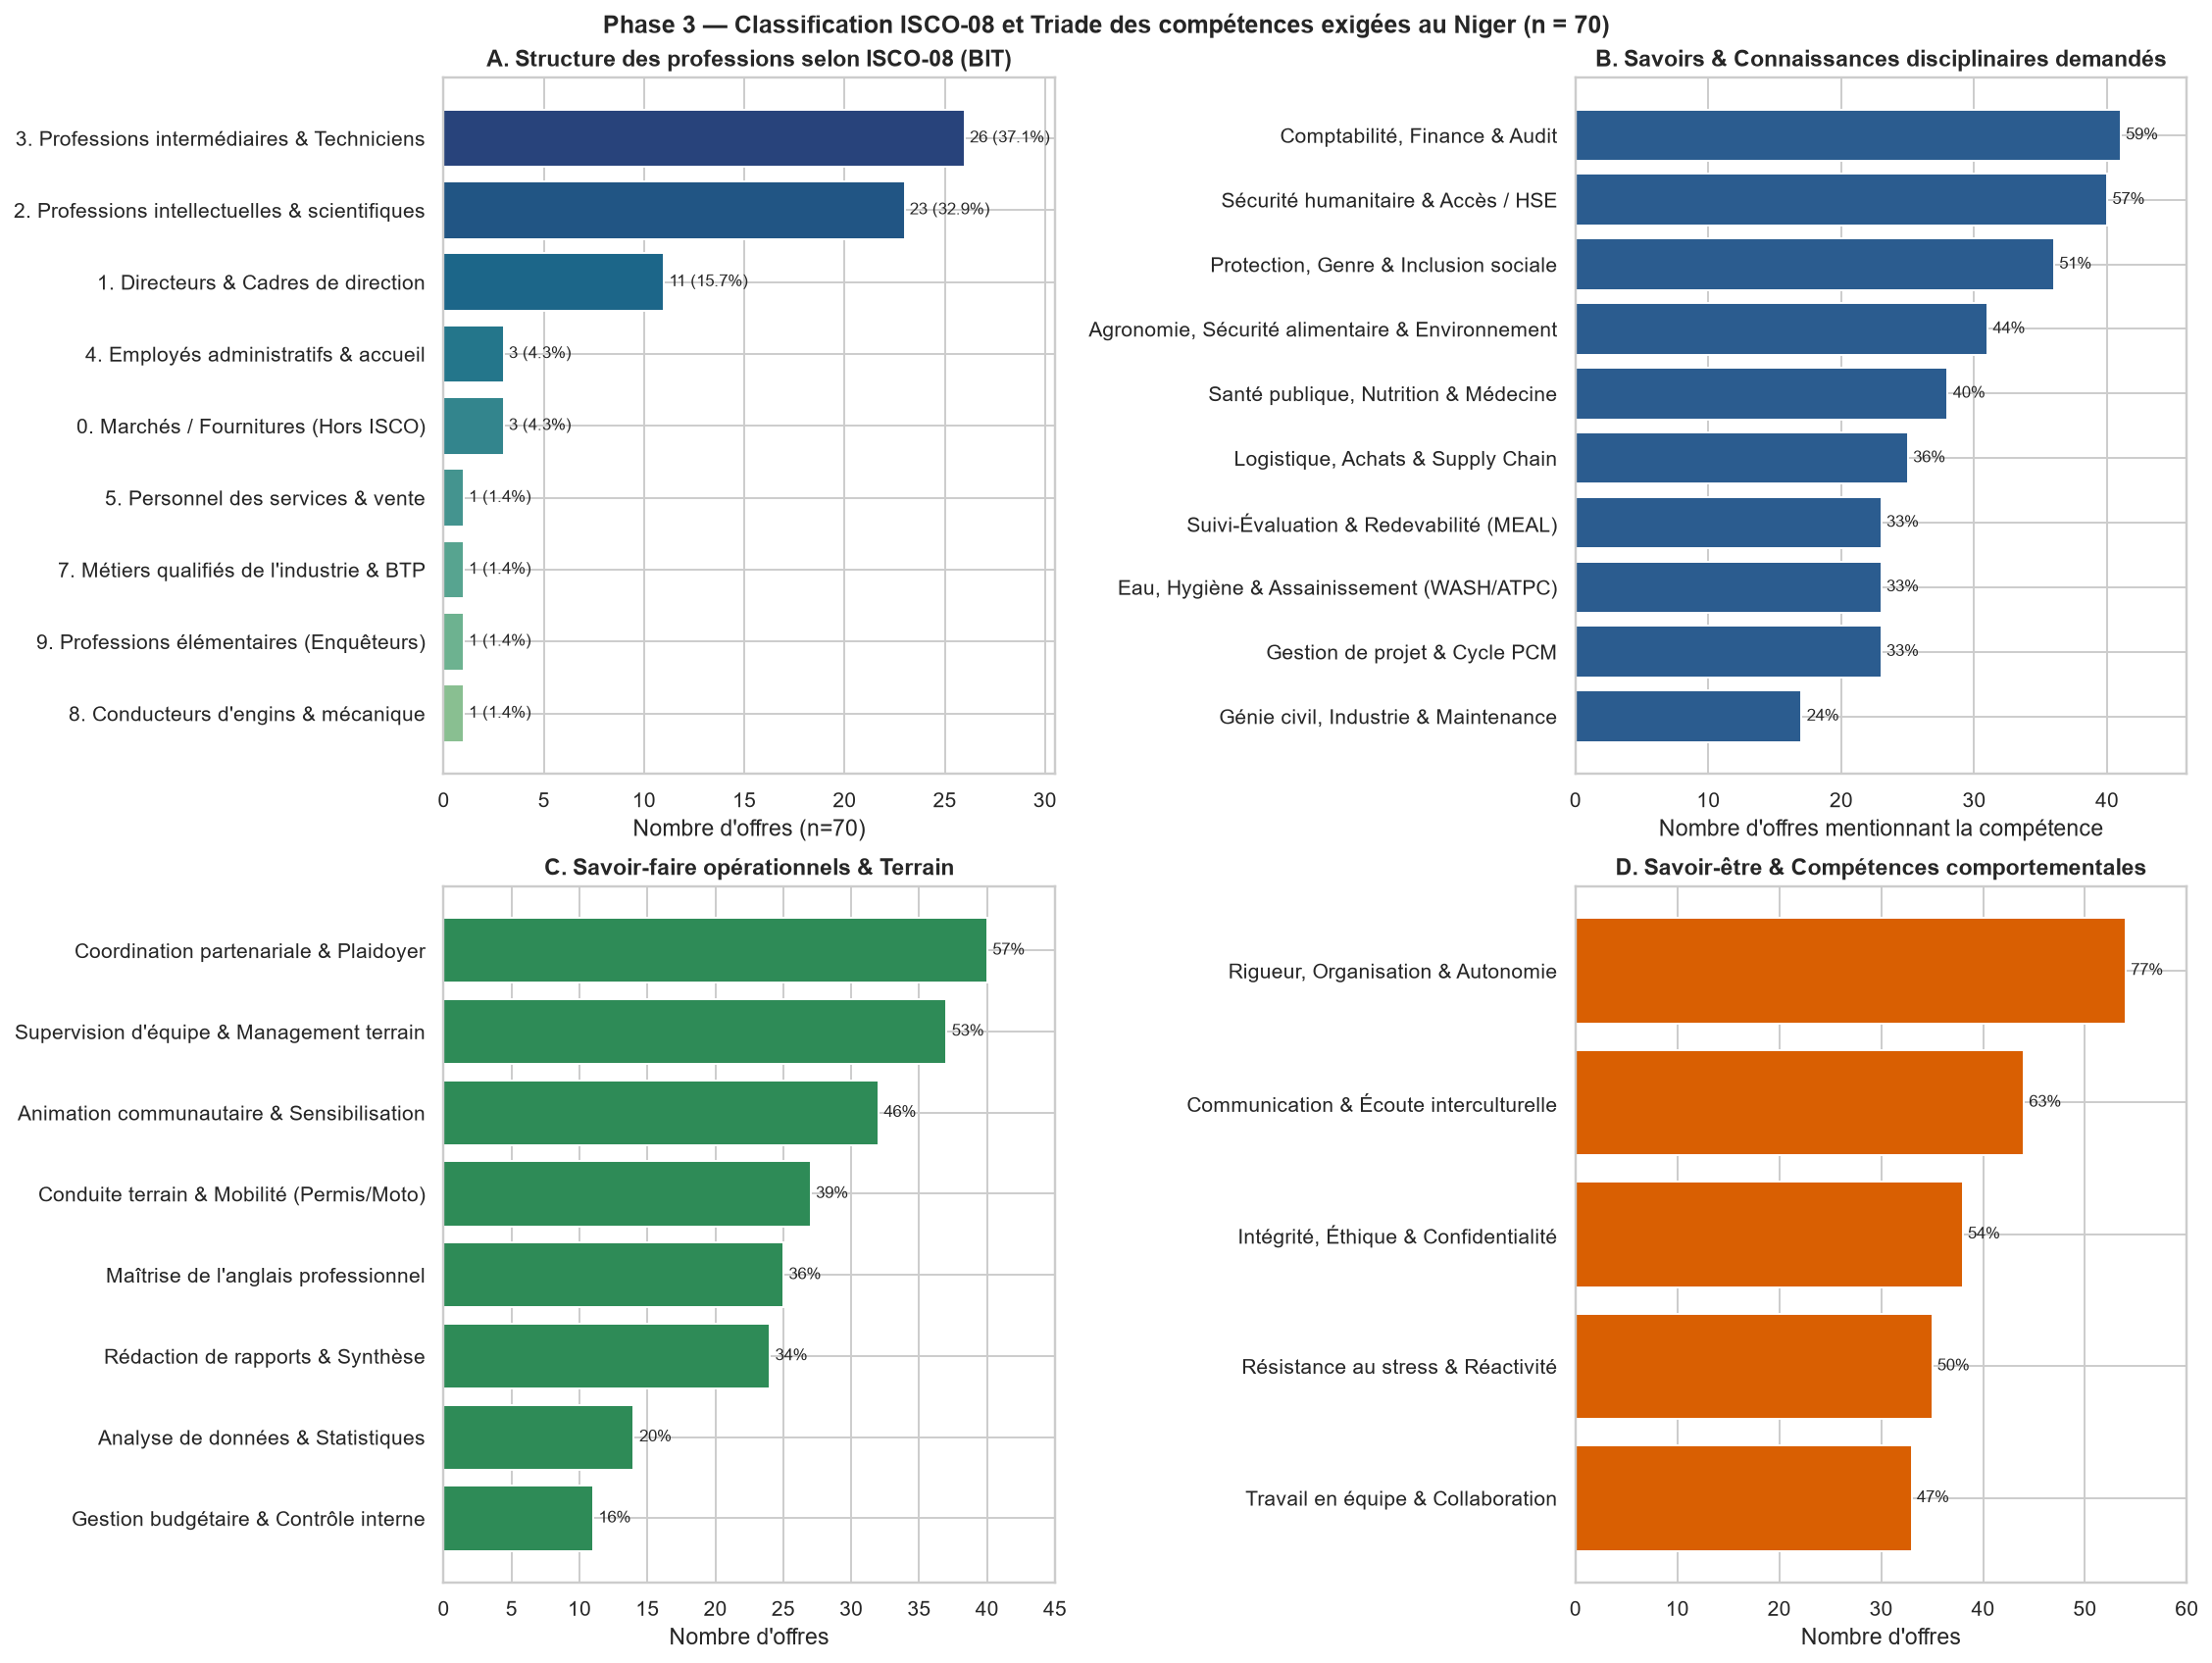

In [6]:
# ==============================================================================
# 4. VISUALISATION SYNTHETIQUE PHASE 3 (2x2)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12), constrained_layout=True)

# A. Grands Groupes ISCO-08
ax1 = axes[0, 0]
isco_c = emp["isco08_groupe"].value_counts().sort_values(ascending=True)
ax1.barh(isco_c.index, isco_c.values, color=sns.color_palette("crest", len(isco_c)))
ax1.set_title("A. Structure des professions selon ISCO-08 (BIT)", fontweight="bold")
ax1.set_xlabel("Nombre d'offres (n=70)")
for i, v in enumerate(isco_c.values):
    ax1.text(v + 0.25, i, f"{v} ({v/len(emp)*100:.1f}%)", va="center", fontsize=8.5)
ax1.set_xlim(0, isco_c.max() + 4.5)

# B. Top Savoirs (Connaissances disciplinaires)
ax2 = axes[0, 1]
sav_c = emp["savoirs"].explode().dropna().value_counts().sort_values(ascending=True)
ax2.barh(sav_c.index, sav_c.values, color="#2b5c8f")
ax2.set_title("B. Savoirs & Connaissances disciplinaires demandés", fontweight="bold")
ax2.set_xlabel("Nombre d'offres mentionnant la compétence")
for i, v in enumerate(sav_c.values):
    ax2.text(v + 0.4, i, f"{v/len(emp)*100:.0f}%", va="center", fontsize=8.5)
ax2.set_xlim(0, sav_c.max() + 5)

# C. Savoir-faire opérationnels
ax3 = axes[1, 0]
sf_c = emp["savoir_faire"].explode().dropna().value_counts().sort_values(ascending=True)
ax3.barh(sf_c.index, sf_c.values, color="#2e8b57")
ax3.set_title("C. Savoir-faire opérationnels & Terrain", fontweight="bold")
ax3.set_xlabel("Nombre d'offres")
for i, v in enumerate(sf_c.values):
    ax3.text(v + 0.4, i, f"{v/len(emp)*100:.0f}%", va="center", fontsize=8.5)
ax3.set_xlim(0, sf_c.max() + 5)

# D. Savoir-être (Soft Skills)
ax4 = axes[1, 1]
se_c = emp["savoir_etre"].explode().dropna().value_counts().sort_values(ascending=True)
ax4.barh(se_c.index, se_c.values, color="#d95f02")
ax4.set_title("D. Savoir-être & Compétences comportementales", fontweight="bold")
ax4.set_xlabel("Nombre d'offres")
for i, v in enumerate(se_c.values):
    ax4.text(v + 0.5, i, f"{v/len(emp)*100:.0f}%", va="center", fontsize=8.5)
ax4.set_xlim(0, se_c.max() + 6)

fig.suptitle("Phase 3 — Classification ISCO-08 et Triade des compétences exigées au Niger (n = 70)", fontsize=13, fontweight="bold")
plt.savefig(BASE_DIR / "phase3_triade_competences.png", bbox_inches="tight")
plt.show()


In [7]:
# ==============================================================================
# 5. EXPORT POUR LE NOTEBOOK 03 (MODELISATION & RECOMMANDATIONS EFTP / ODD 8)
# ==============================================================================
for col in ["savoirs", "savoir_faire", "outils", "savoir_etre"]:
    emp[col + "_str"] = emp[col].apply(lambda lst: " ; ".join(lst) if lst else "Non détecté")

emp.to_csv(BASE_DIR / "offres_niger_nlp.csv", index=False)
print("\nExport terminé : offres_niger_nlp.csv prêt pour le notebook 03.")


Export terminé : offres_niger_nlp.csv prêt pour le notebook 03.
